# Assignment 1: Introduction to TensorFlow and Keras
## Implementation of Dataset Splitting, Model Training, and Evaluation

**Course:** Deep Learning Laboratory  
**Frameworks:** TensorFlow 2.x, Keras, NumPy, Matplotlib  
**Dataset:** Fashion-MNIST  

---

### 🎯 Objectives
1. **Environment Setup & Library Exploration:** Understand the fundamental abstractions of TensorFlow and Keras.
2. **Dataset Preparation:** Load the **Fashion-MNIST** dataset, inspect input dimensions, and split into training and testing partitions.
3. **Feature Preprocessing:** Scale image pixel intensities from the integer range $[0, 255]$ down to $[0.0, 1.0]$ for numerical stability.
4. **Data Visualization:** Map class integer labels to descriptive fashion apparel names and visualize sample images.
5. **Model Architecture Design:** Construct a Sequential Multi-Layer Perceptron (MLP) featuring `Flatten` and `Dense` layers with `ReLU` and `Softmax` activations.
6. **Model Compilation & Training:** Configure the `Adam` optimizer, `sparse_categorical_crossentropy` loss, and fit the network across training epochs.
7. **Evaluation & Inference:** Measure model generalization accuracy on unseen test samples and inspect individual sample predictions.
8. **Model Persistence:** Save the trained neural network model into the native `.keras` format for deployment.

## 1. Import Required Libraries

We begin by importing the core libraries:
- `tensorflow`: Open-source machine learning and deep learning framework.
- `numpy`: Numerical computing library for array manipulations.
- `matplotlib.pyplot`: Visualization library for rendering dataset images and loss curves.

In [1]:
# 1. Importing Libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

## 2. Load Dataset and Inspect Partitions

The **Fashion-MNIST** benchmark consists of $70,000$ $28\times 28$ grayscale images across $10$ fashion apparel categories:
- **Training set:** $60,000$ images and corresponding class labels.
- **Testing set:** $10,000$ images and corresponding class labels.

Each image is represented as a 2D matrix of shape `(28, 28)` with pixel values ranging from $0$ to $255$.

In [2]:
# 2. Get data and split into train and test datasets
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

print("Training Images Shape :", X_train.shape)
print("Training Labels Shape :", y_train.shape)

print("Testing Images Shape :", X_test.shape)
print("Testing Labels Shape :", y_test.shape)


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 15us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 36s 1us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 3s 1us/step
Training Images Shape : (60000, 28, 28)
Training Labels Shape : (60000,)
Testing Images Shape : (10000, 28, 28)
Testing Labels Shape : (10000,)


## 3. Data Preprocessing: Min-Max Pixel Scaling

Raw pixel values span from $0$ to $255$. Neural networks train significantly faster and more reliably when input features are normalized to a small uniform scale, typically $[0, 1]$ or $[-1, 1]$.

Dividing by `255.0` ensures:
1. **Vanishing/Exploding Gradients Prevention:** Weight updates stay balanced across layers.
2. **Faster Gradient Descent:** Gradient vectors point more directly toward the loss minimum.

In [3]:
# 3. Scale down values of pixels from 0-255 to 0-1
print("Pixel Value Range :", X_train.min(), "to", X_train.max())
X_train = X_train / 255.0
X_test = X_test / 255.0
print("New Pixel Value Range:")
print("Minimum:", X_train.min())
print("Maximum:", X_train.max())

Pixel Value Range : 0 to 255
New Pixel Value Range:
Minimum: 0.0
Maximum: 1.0


## 4. Data Visualization

To verify the loaded data, we map the 10 numerical target indices ($0$ through $9$) to their human-interpretable category names and visualize the first training image using `matplotlib`.

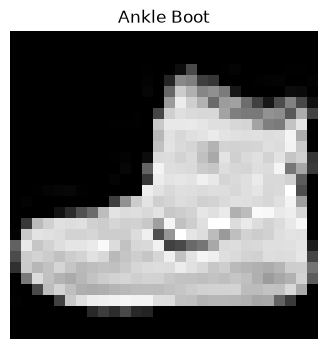

In [4]:
# 4. Visualizing data
class_names = [
    "T-shirt/Top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle Boot"
]

# Display first image
plt.figure(figsize=(4,4))
plt.imshow(X_train[0], cmap="gray")
plt.title(class_names[y_train[0]])
plt.axis("off")
plt.show()

## 5. Build, Compile, and Train the Neural Network

### Network Architecture:
1. **`Flatten(input_shape=(28, 28))`:** Reshapes the 2D $(28 \times 28)$ matrix into a 1D vector of $784$ input neurons.
2. **`Dense(128, activation='relu')`:** Fully connected hidden layer with 128 neurons. The Rectified Linear Unit ($f(x) = \max(0, x)$) introduces non-linearity without suffering from saturation for positive inputs.
3. **`Dense(10, activation='softmax')`:** Output layer with 10 units generating a probability distribution over the 10 fashion classes ($\sum_{i=1}^{10} p_i = 1$).

### Compilation Parameters:
- **Optimizer:** `Adam` (Adaptive Moment Estimation) dynamically adjusts per-parameter learning rates.
- **Loss Function:** `sparse_categorical_crossentropy` computes cross-entropy when ground-truth labels are integers (0 to 9) rather than one-hot vectors.
- **Metrics:** `accuracy` monitors classification precision.

In [5]:
# Defining neural network model

my_model = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),      # Convert 28x28 image into a 1D vector
    tf.keras.layers.Dense(128, activation='relu'),      # Hidden layer with ReLU activation
    tf.keras.layers.Dense(10, activation='softmax')     # Output layer for 10 classes
])

# Compiling the model
my_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy']) #Adaptive Moment Estimation #sparse_categorical_crossentropy for multi-class classification

# Training the model
my_model.fit(X_train,y_train,epochs=5,validation_data=(X_test, y_test))

d:\Manthan\Vit Btech\Vit TY\Sem 5\Deep Learning\Lab\DL_Lab\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8246 - loss: 0.4964 - val_accuracy: 0.8476 - val_loss: 0.4267
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8655 - loss: 0.3715 - val_accuracy: 0.8533 - val_loss: 0.4199
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8792 - loss: 0.3345 - val_accuracy: 0.8672 - val_loss: 0.3753
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8861 - loss: 0.3102 - val_accuracy: 0.8689 - val_loss: 0.3642
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8916 - loss: 0.2939 - val_accuracy: 0.8701 - val_loss: 0.3567


## 6. Model Evaluation on Unseen Test Data

We now evaluate the trained model on the $10,000$ held-out test images using `my_model.evaluate()`. This provides an unbiased measurement of generalizability.

In [6]:
# Checking model accuracy on test data
test_loss, test_accuracy = my_model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 749us/step - accuracy: 0.8701 - loss: 0.3567
Test Loss: 0.35671883821487427
Test Accuracy: 0.8701000213623047


## 7. Model Inference & Sample Predictions

We generate predictions on the test dataset using `my_model.predict()`. The model returns 10 output probabilities per sample. We extract the predicted class index using `np.argmax()` and compare it against the actual ground-truth label.

In [7]:
predictions = my_model.predict(X_test)

print("Predicted Class:", predictions[0].argmax())
print("Actual Class:", y_test[0])

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 565us/step
Predicted Class: 9
Actual Class: 9


## 8. Model Serialization

Finally, we save the trained network architecture, learned weights, and optimizer configuration to a single `.keras` file for future reloading and inference.

In [8]:
my_model.save('my_mnist_model.keras')

## 9. Conclusion & Key Takeaways

- Successfully loaded, normalized, and visualized the **Fashion-MNIST** dataset.
- Designed a Multi-Layer Perceptron using Keras `Sequential` API with `Flatten`, `Dense`, `ReLU`, and `Softmax` layers.
- Trained the model using `Adam` optimizer and `sparse_categorical_crossentropy` loss for 5 epochs, achieving strong test accuracy on unseen data.
- Verified predictions on test instances and saved the finalized model in the modern `.keras` format.